Jacobi constant at L1: 3.188341


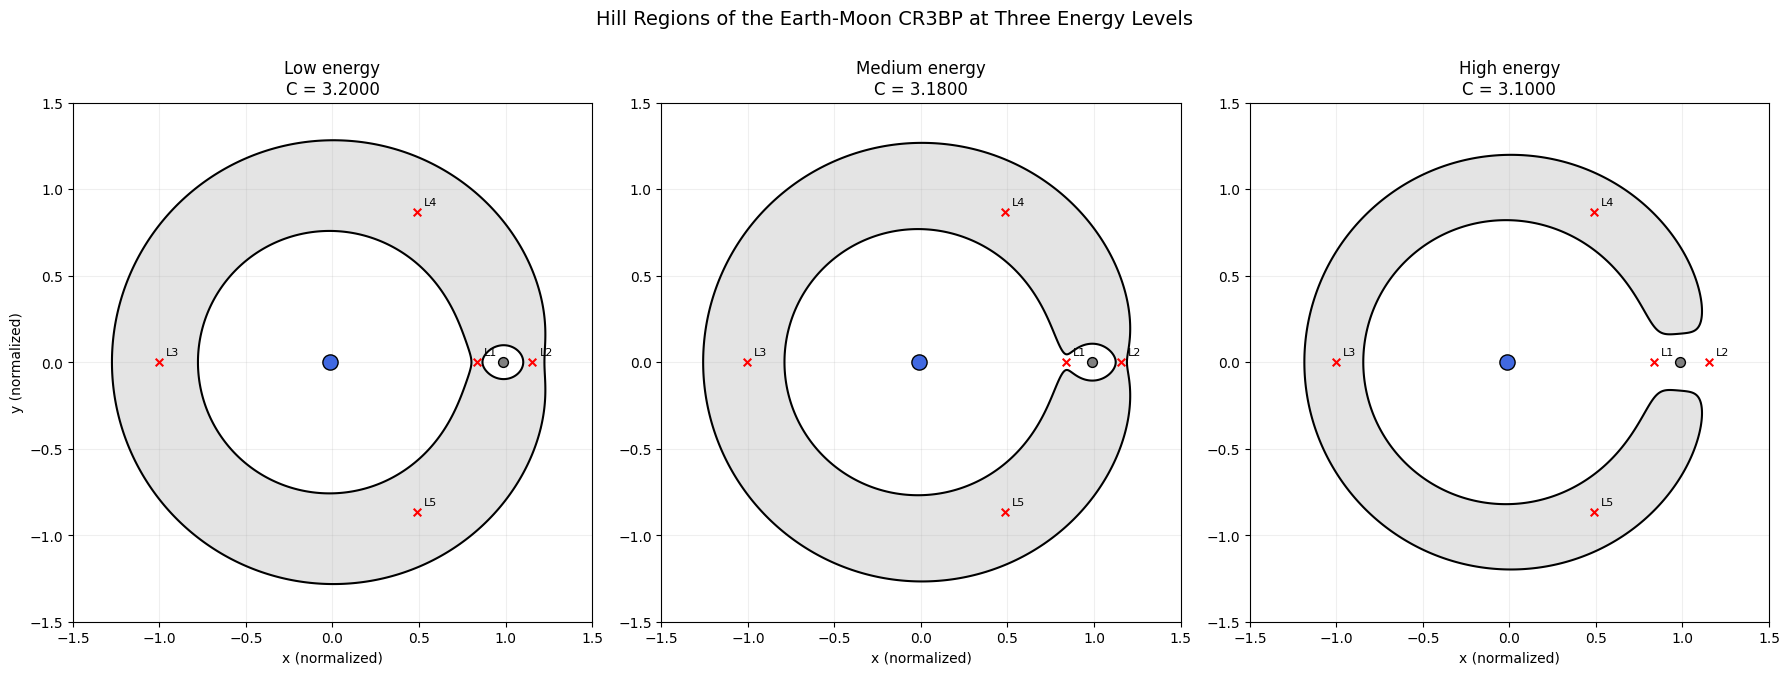

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, '../src')
from cr3bp import effective_potential, find_lagrange_points, jacobi_constant, MU_EARTH_MOON

mu = MU_EARTH_MOON
lps = find_lagrange_points(mu)

# 1. Build the grid
n = 800  # grid resolution — higher = smoother curves but slower
x = np.linspace(-1.5, 1.5, n)
y = np.linspace(-1.5, 1.5, n)
X, Y = np.meshgrid(x, y)

# 2. Evaluate 2*Omega on the whole grid at once (vectorized)
two_Omega = 2 * effective_potential(X, Y, mu)

# 3. Pick a Jacobi constant to visualize
#    The Jacobi values AT the Lagrange points are natural reference values,
#    because that's where necks open/close. 
C_L1 = jacobi_constant([lps['L1'][0], lps['L1'][1], 0, 0], mu)
C_L2 = jacobi_constant([lps['L2'][0], lps['L2'][1], 0, 0], mu)
C_L3 = jacobi_constant([lps['L3'][0], lps['L3'][1], 0, 0], mu)
C_L4 = jacobi_constant([lps['L4'][0], lps['L4'][1], 0, 0], mu)
C_L5 = jacobi_constant([lps['L5'][0], lps['L5'][1], 0, 0], mu)

print(f"Jacobi constant at L1: {C_L1:.6f}")
C1 = 3.2  # just a bit above L1
C2 = 3.18
C3 = 3.1

C_values = [C1, C2, C3]          
titles = ['Low energy', 'Medium energy', 'High energy']  

# 4. Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for i, C in enumerate(C_values):
    ax = axes[i]  

    # Forbidden region: where 2*Omega < C  (velocity would be imaginary)
    # We shade this. contourf with levels from min up to C.
    forbidden = np.where(two_Omega < C, 1, 0)
    ax.contourf(X, Y, forbidden, levels=[0.5, 1.5], colors=['lightgray'], alpha=0.6)

    # The zero-velocity curve itself: 2*Omega == C
    ax.contour(X, Y, two_Omega, levels=[C], colors=['black'], linewidths=1.5)

    # Overlay the primaries and Lagrange points
    ax.scatter([-mu], [0], color='royalblue', s=120, zorder=5, edgecolor='black', label='Earth')
    ax.scatter([1 - mu], [0], color='gray', s=50, zorder=5, edgecolor='black', label='Moon')
    for name, (lx, ly) in lps.items():
        ax.scatter([lx], [ly], color='red', s=30, marker='x', zorder=5)
        ax.annotate(name, (lx, ly), textcoords='offset points', xytext=(5, 5), fontsize=8)

    ax.set_aspect('equal')
    ax.set_xlabel('x (normalized)')
    if i == 0:
        ax.set_ylabel('y (normalized)')   # only leftmost panel needs the y-label
    ax.set_title(f'{titles[i]}\nC = {C:.4f}')
    ax.grid(True, alpha=0.2)
    
fig.suptitle('Hill Regions of the Earth-Moon CR3BP at Three Energy Levels', fontsize=14) 
plt.tight_layout()
plt.show()